# Iris Flower Classification #

## 1. Understand the Dataset

##### Step 1 - Import Libraries

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score, classification_report



##### Step 2 - Load Dataset

In [2]:
iris =  load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)

df['species'] = iris.target

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


##### Step 3 - Explore Dataset

In [3]:
df.shape

(150, 5)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [5]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [6]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

In [7]:
df['species'].value_counts()

species
0    50
1    50
2    50
Name: count, dtype: int64

##### Step 4 - Class Distribution

In [8]:
df['species_name'] =  df['species'].map({
    0:"Setose",
    1:'Versicolor',
    2:"Virginca"
})

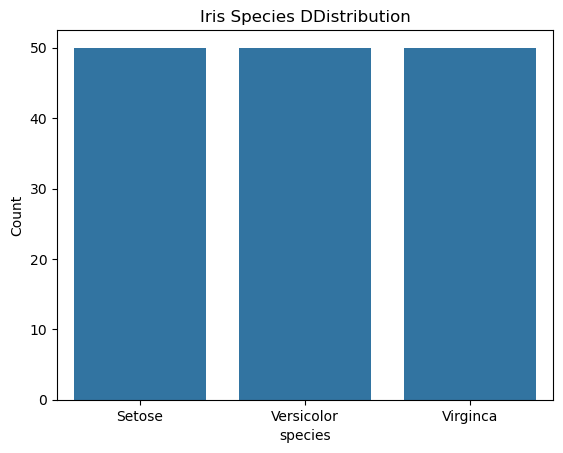

In [9]:
sns.countplot(data=df, x="species_name")

plt.title("Iris Species DDistribution")
plt.xlabel("species")
plt.ylabel("Count")
plt.show()

##### Step 5 - Feature Distribution

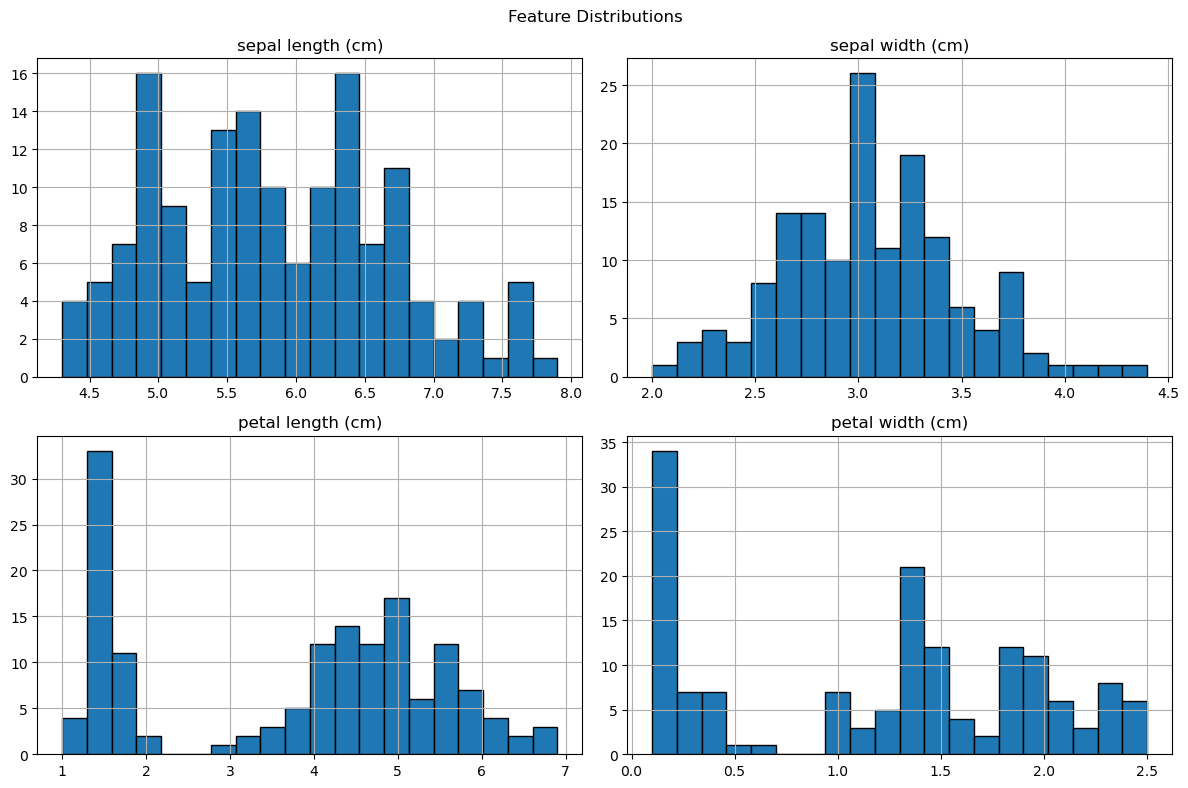

In [10]:
features = iris.feature_names

df[features].hist(
    figsize=(12,8),
    bins=20,
    edgecolor='black'
)

plt.suptitle("Feature Distributions")
plt.tight_layout()
plt.show()

##### Step 6 - Pairplot

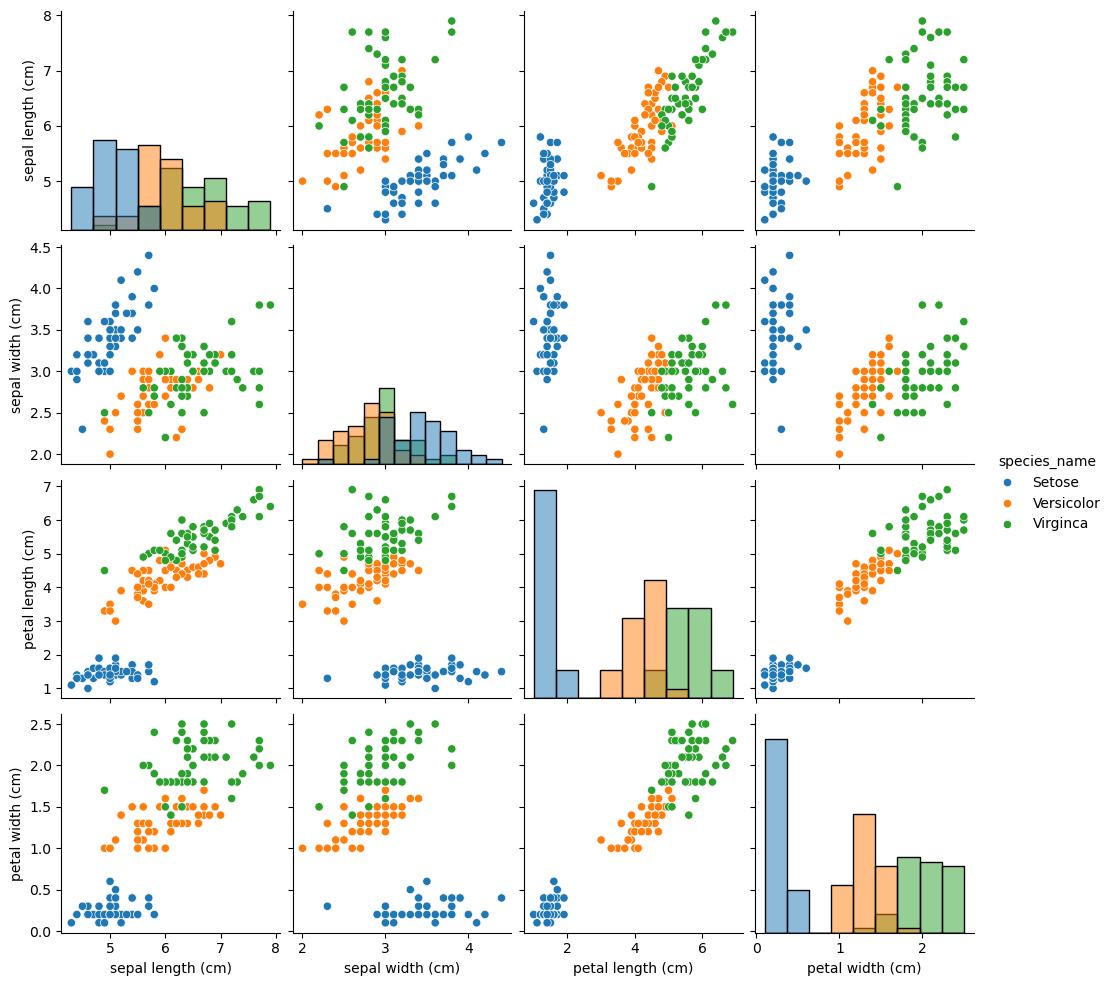

In [11]:
sns.pairplot(
    df,
    vars=features,
    hue='species_name',
    diag_kind="hist"
)

plt.show()

##### Step 7 - Correlation Heatmap

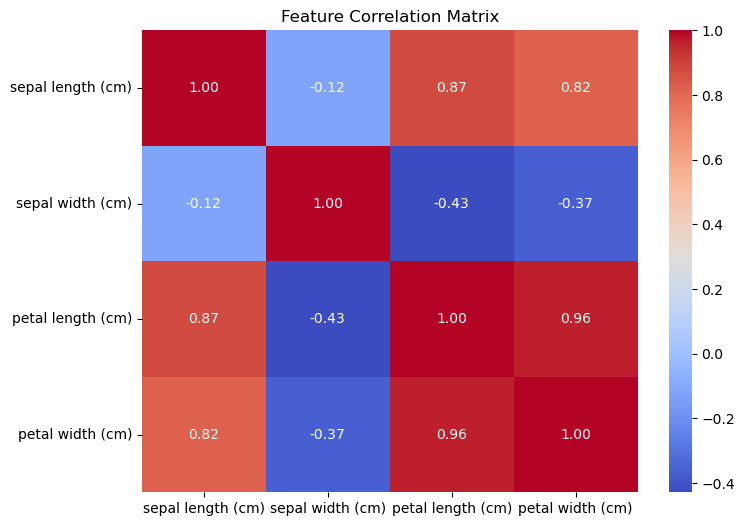

In [12]:
corr = df[features].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")
plt.show()


##### Step 8 - Boxplots

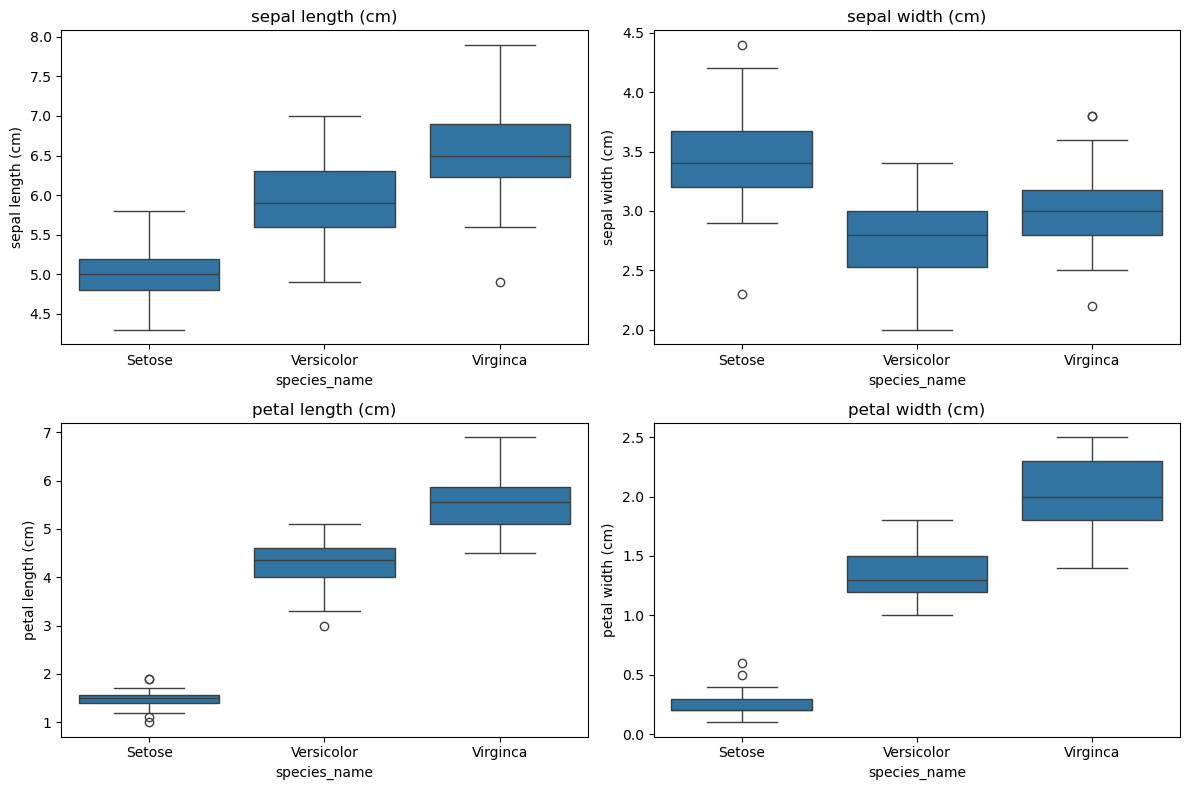

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flat, features):
    sns.boxplot(
        data=df,
        x="species_name",
        y=feature,
        ax=ax
    )
    ax.set_title(feature)

plt.tight_layout()
plt.show()


## 2. Data Preprocessing

##### Step 1 - Checking Data Quality

In [14]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
species_name         0
dtype: int64

In [15]:
df.dtypes

sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species                int64
species_name          object
dtype: object

##### Step 2 - Separating Features and Target

In [16]:
x = df[iris.feature_names]
y = df['species']

##### Step 3 - Train/Test Split

In [17]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
    )


##### Step 4 - Feature Scaling

In [18]:
scaler = StandardScaler()

x_train_scaled =  scaler.fit_transform(x_train)
x_test_scaled =  scaler.transform(x_test)

In [19]:
scaled_df = pd.DataFrame(
    x_train_scaled,
    columns=x_train.columns
    )

scaled_df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-1.721568,-0.332101,-1.345722,-1.323276
1,-1.124492,-1.227655,0.414505,0.651763
2,1.144395,-0.555990,0.584850,0.256755
3,-1.124492,0.115676,-1.288941,-1.454945
4,-0.408002,-1.227655,0.130598,0.125086


## 3. Model Training 

Why choose Logistic Regression for an Iris project?


Because it is suitable as a starting point for these reasons:
- Relatively easy to understand: You learn weights (Weights) for Features.
- Fast to train: especially since Iris data is small.
- Multiclass Classification supports: We have 3 types, not 2.
- Probabilities appear: We can know the probability of each type using predict_proba().
- Baseline Model is excellent: we can compare it to KNN and Decision Tree later.

### Create & Train

In [20]:
model = LogisticRegression(max_iter=1000, solver="lbfgs")

In [21]:
model.fit(x_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


### Make Predictions

In [22]:
y_pred  = model.predict(x_test_scaled)
y_pred

array([0, 2, 1, 1, 0, 1, 0, 0, 2, 1, 2, 2, 2, 1, 0, 0, 0, 1, 1, 2, 0, 2,
       1, 1, 2, 2, 1, 0, 2, 0])

In [23]:
y_test.to_numpy()

array([0, 2, 1, 1, 0, 1, 0, 0, 2, 1, 2, 2, 2, 1, 0, 0, 0, 1, 1, 2, 0, 2,
       1, 2, 2, 1, 1, 0, 2, 0])

In [24]:
results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})

results["Actual_Name"] = results["Actual"].map(
    dict(enumerate(iris.target_names))
)

results["Predicted_Name"] = results["Predicted"].map(
    dict(enumerate(iris.target_names))
)

results.head()


,Actual,Predicted,Actual_Name,Predicted_Name
0,0,0,setosa,setosa
1,2,2,virginica,virginica
2,1,1,versicolor,versicolor
3,1,1,versicolor,versicolor
4,0,0,setosa,setosa


In [25]:
probabilities = model.predict_proba(x_test_scaled)

probabilities[:5]

array([[9.78818005e-01, 2.11816311e-02, 3.63821812e-07],
       [3.79836951e-03, 3.69220168e-01, 6.26981463e-01],
       [1.48799040e-01, 8.42474895e-01, 8.72606441e-03],
       [9.54449962e-02, 8.94618634e-01, 9.93636953e-03],
       [9.88493051e-01, 1.15067767e-02, 1.72549650e-07]])

### Evaluation

In [26]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.2%}")

Accuracy: 93.33%


### Predict a New Flower

In [27]:
new_flower = pd.DataFrame(
    [[5.0, 3.5, 1.5, 0.2]],
    columns=iris.feature_names
)

new_flower_scaled = scaler.transform(new_flower)

prediction = model.predict(new_flower_scaled)

flower_name = iris.target_names[prediction[0]]

flower_name


np.str_('setosa')

In [28]:
probabilities = model.predict_proba(
    new_flower_scaled
)[0]

for flower, prob in zip(iris.target_names, probabilities):
    print(f"{flower}: {prob:.2%}")

setosa: 98.27%
versicolor: 1.73%
virginica: 0.00%


## 4. Model Evaluation

In [29]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[10,  0,  0],
       [ 0,  9,  1],
       [ 0,  1,  9]])

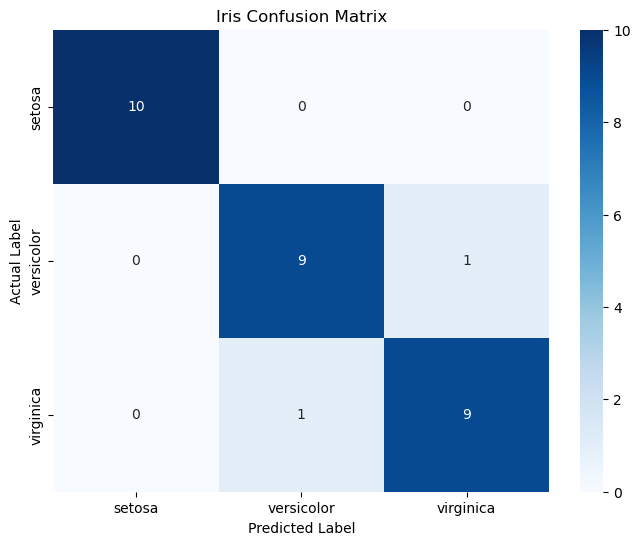

In [30]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Iris Confusion Matrix")

plt.show()


In [31]:
accuracy = accuracy_score(y_test, y_pred)
print(f'{accuracy:.2%}')

93.33%


In [32]:
precision = precision_score(y_test, y_pred, average=None)

In [33]:
for name, score in zip(iris.target_names, precision):
    print(f"{name}: {score:.2%}")

setosa: 100.00%
versicolor: 90.00%
virginica: 90.00%


In [34]:
recall = recall_score(y_test, y_pred, average=None)

In [35]:
for name, score in zip(iris.target_names, recall):
    print(f"{name}: {score:.2%}")

setosa: 100.00%
versicolor: 90.00%
virginica: 90.00%


In [ ]:
f1 = f1_score(y_test, y_pred, average=None)

In [37]:
for name, score in zip(iris.target_names, f1):
    print(f"{name}: {score:.2%}")

setosa: 100.00%
versicolor: 90.00%
virginica: 90.00%


In [38]:

print("Macro F1:", f1_score(
    y_test, y_pred, average="macro"
))

print("Weighted F1:", f1_score(
    y_test, y_pred, average="weighted"
))

print("Micro F1:", f1_score(
    y_test, y_pred, average="micro"
))


Macro F1: 0.9333333333333332
Weighted F1: 0.9333333333333333
Micro F1: 0.9333333333333333


In [41]:
report = classification_report(y_test, y_pred, 
                               target_names=iris.target_names,
                               digits=2)

In [43]:
print(report)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [ ]:
# Create a copy of test features
errors = x_test.copy()

# Add actual flower names
errors["Actual"] = y_test.map(
    dict(enumerate(iris.target_names))
)

# Add predicted flower names
errors["Predicted"] = pd.Series(
    y_pred,
    index=y_test.index
).map(dict(enumerate(iris.target_names)))

# Keep only wrong predictions
errors = errors[
    errors["Actual"] != errors["Predicted"]
]

errors


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Actual,Predicted
134,6.1,2.6,5.6,1.4,virginica,versicolor
77,6.7,3.0,5.0,1.7,versicolor,virginica


In [ ]:
wrong_mask = y_test.to_numpy() != y_pred

wrong_probabilities = model.predict_proba(
    x_test_scaled[wrong_mask]
)

print(wrong_probabilities.round(4))


[[0.0013 0.5145 0.4842]
 [0.0015 0.4417 0.5569]]


## 5. Save Model

In [47]:
import joblib

joblib.dump(model, "iris_model.joblib")
joblib.dump(scaler, "iris_scaler.joblib")

print("Model and Scaler saved successfully!")


Model and Scaler saved successfully!


In [48]:

loaded_model = joblib.load("iris_model.joblib")

loaded_scaler = joblib.load("iris_scaler.joblib")

print("Model loaded successfully!")


Model loaded successfully!


In [49]:

# Create new flower data
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

# Scale the input
new_flower_scaled = loaded_scaler.transform(new_flower)

# Predict species
prediction = loaded_model.predict(new_flower_scaled)

# Display result
print("Predicted Species:", iris.target_names[prediction[0]])


Predicted Species: setosa
